# 8. Constant-pressure simulation (NPT): Berendsen and isotropic barostats

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 4–7

This chapter builds and verifies the core algorithms for constant-pressure simulation (npt): berendsen and isotropic barostats in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 8.1 Physical principles and governing equations

In the isothermal–isobaric ($NPT$) ensemble, the cubic box volume $V(t) = L(t)^3$ fluctuates to balance the internal virial pressure $P(t)$ against the external target pressure $P_0$:

$$\mu = \left[1 - \frac{\kappa_T \Delta t}{\tau_P}(P_0 - P(t))\right]^{1/3}, \qquad L \leftarrow \mu L, \qquad \mathbf{r}_i \leftarrow \mu \mathbf{r}_i. \tag{8.1}$$

## 8.2 Inside the algorithm

In [2]:
pos_8, L_8 = es.make_fcc_lattice(3, rho=0.60)  # Start deliberately under-dense
vel_8 = es.init_velocities(len(pos_8), 1.0, rng=rng)
f_fn = lambda p, L: es.lj_forces_all_pairs(p, L, rc=2.5, shifted=True)
f_8, _, vir_8 = f_fn(pos_8, L_8)

rho_hist, P_hist = [], []
P_target = 1.5
for step in range(220):
    pos_8, vel_8, f_8, _, vir_8, _ = es.velocity_verlet_step(pos_8, vel_8, f_8, 0.005, L_8, f_fn)
    vel_8 = es.bussi_csvr_thermostat(vel_8, 1.0, 0.005, 0.05, rng)
    _, T_c = es.kinetic_energy_and_temp(vel_8)
    rho_c = len(pos_8) / (L_8**3)
    P_c = rho_c * T_c + vir_8 / (3.0 * L_8**3)
    pos_8, L_8 = es.berendsen_barostat_scale(pos_8, L_8, P_c, P_target, 0.005, tau_P=0.2, kappa_T=0.08)
    rho_hist.append(len(pos_8) / (L_8**3))
    P_hist.append(P_c)

## 8.3 Checks

NPT equilibration (T*=1.0, P*=1.5): <rho*> = 0.785, <P*> = 1.398


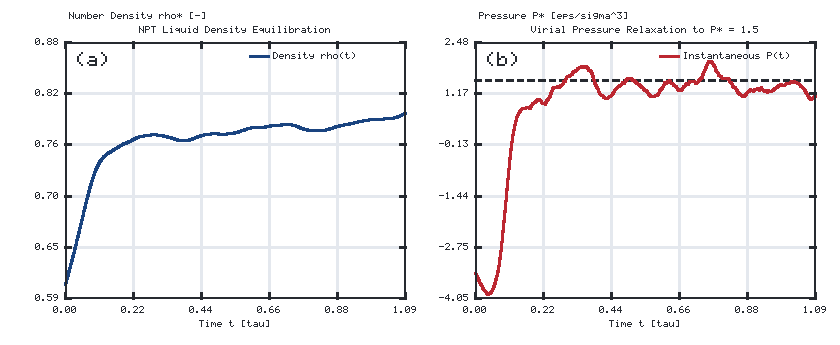

In [3]:
rho_eq = float(np.mean(rho_hist[120:]))
P_eq = float(np.mean(P_hist[120:]))
print(f"NPT equilibration (T*=1.0, P*=1.5): <rho*> = {rho_eq:.3f}, <P*> = {P_eq:.3f}")
assert 0.65 < rho_eq < 0.90
assert np.isclose(P_eq, P_target, atol=0.45)

t_8 = np.arange(len(rho_hist)) * 0.005
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(t_8, rho_hist, "b-", label="Density rho(t)")
ax1.set_xlabel("Time t [tau]"); ax1.set_ylabel("Number Density rho* [-]")
ax1.set_title("(a) NPT Liquid Density Equilibration"); panel_label(ax1, "(a)")

ax2.plot(t_8, P_hist, "r-", label="Instantaneous P(t)")
ax2.axhline(P_target, color="k")
ax2.set_xlabel("Time t [tau]"); ax2.set_ylabel("Pressure P* [eps/sigma^3]")
ax2.set_title("(b) Virial Pressure Relaxation to P* = 1.5"); panel_label(ax2, "(b)")
plt.show()

**Figure 8.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 8.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **Ideal-gas NPT equation of state:** Turn off pair forces (`force_fn` returns zeros) and verify that `berendsen_barostat_scale` drives the density to the exact ideal-gas value $\rho = P_0 / T_0$.
2. **Isothermal compressibility estimate:** Estimate $\kappa_T = \frac{\mathrm{Var}(V)}{\langle V \rangle k_B T}$ from volume fluctuations.
3. **High-pressure compression:** Increase $P_0$ from $1.5$ to $4.0$ and measure the resulting density increase $\Delta \rho^*$.

Worked solutions are provided in [08_solutions.ipynb](../../solutions/part2_ensembles/08_solutions.ipynb).

## Suggested references

- G. Bussi, D. Donadio, and M. Parrinello, *J. Chem. Phys.* **126**, 014101 (2007).
- B. Leimkuhler and C. Matthews, *Molecular Dynamics: With Deterministic and Stochastic Numerical Methods* (Springer, 2015).

---

**Next:** [9. Metropolis Monte Carlo in the canonical ensemble (NVT-MC)](../part3_monte_carlo/09_metropolis_nvt_mc.ipynb)